In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All imports worked")

All imports worked


In [2]:
tickers = ["AAPL", "MSFT", "JNJ", "JPM", "XOM", "PG", "KO", "NVDA", "WMT", "CAT"]

prices = yf.download(tickers, start="2015-01-01", end="2024-12-31")["Close"]

prices.tail()

[*********************100%***********************]  10 of 10 completed


Ticker,AAPL,CAT,JNJ,JPM,KO,MSFT,NVDA,PG,WMT,XOM
Date,,,,,,,,,,
2024-12-23,253.430847,357.768005,138.723969,230.179581,59.437828,429.338989,139.305832,160.216690,88.927071,100.520279
2024-12-24,256.339722,359.902496,139.277847,233.964584,59.876133,433.363556,139.854416,161.007736,91.220367,100.614822
2024-12-26,257.153809,359.461914,139.020004,234.766006,59.618862,432.160126,139.565155,162.170471,91.328636,100.699936
2024-12-27,253.748550,357.249023,138.513870,232.863846,59.504528,424.683075,136.652756,161.570038,90.216446,100.690475
2024-12-30,250.382950,355.437622,136.880920,231.077591,59.104332,419.060425,137.131516,159.244614,89.143600,100.009621


In [3]:
prices.to_csv('prices.csv')
print(prices.shape)

(2515, 10)


In [4]:
returns = prices.pct_change().dropna()

returns.head()

Ticker,AAPL,CAT,JNJ,JPM,KO,MSFT,NVDA,PG,WMT,XOM
Date,,,,,,,,,,
2015-01-05,-0.028171,-0.052786,-0.006984,-0.031045,0.000000,-0.009196,-0.016890,-0.004755,-0.002911,-0.027361
2015-01-06,0.000094,-0.006434,-0.004913,-0.025929,0.007594,-0.014678,-0.030318,-0.004555,0.007706,-0.005316
2015-01-07,0.014022,0.015496,0.022076,0.001526,0.012482,0.012706,-0.002605,0.005246,0.026532,0.010132
2015-01-08,0.038423,0.010249,0.007863,0.022346,0.012096,0.029418,0.037617,0.011436,0.021106,0.016645
2015-01-09,0.001072,-0.011949,-0.013630,-0.017387,-0.011032,-0.008405,0.004028,-0.009331,-0.012380,-0.001410


In [8]:
ann_return = returns.mean() * 252
ann_std = returns.std() * (252 ** 0.5)
ann_var = returns.var() * 252
summary = pd.DataFrame({"Return": ann_return, "Standard_Deviation": ann_std, "Variance": ann_var})

summary

,Return,Standard_Deviation,Variance
Ticker,,,
AAPL,0.274956,0.284663,0.081033
CAT,0.208913,0.297691,0.088620
JNJ,0.075649,0.180543,0.032596
JPM,0.199055,0.273754,0.074941
KO,0.086546,0.177891,0.031645
MSFT,0.273381,0.271430,0.073674
NVDA,0.683911,0.486098,0.236291
PG,0.106767,0.184745,0.034131
WMT,0.157828,0.211305,0.044650


In [6]:
ann_cov = returns.cov() * 252
ann_cov

Ticker,AAPL,CAT,JNJ,JPM,KO,MSFT,NVDA,PG,WMT,XOM
Ticker,,,,,,,,,,
AAPL,0.081033,0.032447,0.017731,0.032419,0.018629,0.052759,0.074549,0.019375,0.018664,0.023984
CAT,0.032447,0.088620,0.017644,0.049213,0.018751,0.031664,0.049011,0.014267,0.014008,0.046629
JNJ,0.017731,0.017644,0.032596,0.019746,0.016502,0.018835,0.014996,0.017921,0.013878,0.016217
JPM,0.032419,0.049213,0.019746,0.074941,0.022034,0.032796,0.044070,0.017075,0.014484,0.042249
KO,0.018629,0.018751,0.016502,0.022034,0.031645,0.019445,0.016906,0.020509,0.013792,0.019482
MSFT,0.052759,0.031664,0.018835,0.032796,0.019445,0.073674,0.079351,0.021069,0.019370,0.021286
NVDA,0.074549,0.049011,0.014996,0.044070,0.016906,0.079351,0.236291,0.018717,0.021640,0.027245
PG,0.019375,0.014267,0.017921,0.017075,0.020509,0.021069,0.018717,0.034131,0.017561,0.013115
WMT,0.018664,0.014008,0.013878,0.014484,0.013792,0.019370,0.021640,0.017561,0.044650,0.011750


In [10]:
n_assets=len(tickers)
n_assets

10

In [17]:
weights=np.random.random(10)

weights = weights / np.sum(weights)

In [20]:
port_return = np.sum(weights*ann_return)
print(weights)
print(ann_return)
print(port_return)

[0.18431437 0.18399828 0.01299022 0.00702011 0.08387873 0.11692894
 0.19502703 0.05233694 0.03307513 0.13043026]
Ticker
AAPL    0.274956
CAT     0.208913
JNJ     0.075649
JPM     0.199055
KO      0.086546
MSFT    0.273381
NVDA    0.683911
PG      0.106767
WMT     0.157828
XOM     0.095348
dtype: float64
0.2873489322639901


In [22]:
port_var = (weights.T @ ann_cov @ weights)
print(port_var)

0.047366229742310965


In [23]:
n_portfolios=10000

results = np.zeros((n_portfolios, 3))
all_weights = np.zeros((n_portfolios, n_assets))
for i in range(n_portfolios):
    w=np.random.random(n_assets)
    w = w/np.sum(w)
    all_weights[i, :] = w
    ret=np.sum(w*ann_return)
    vol=np.sqrt(w.T @ ann_cov @ w)
    results[i,0] = ret
    results[i,1] = vol
    results[i,2] = ret/vol

print(results.shape)

(10000, 3)


In [24]:
portfolios = pd.DataFrame(results, columns=['Return','Volatility','Sharpe_Ratio'])
portfolios.head()

,Return,Volatility,Sharpe_Ratio
0,0.229736,0.186768,1.230063
1,0.180161,0.158569,1.136169
2,0.202106,0.179030,1.128891
3,0.247557,0.198276,1.248545
4,0.243368,0.179707,1.354247


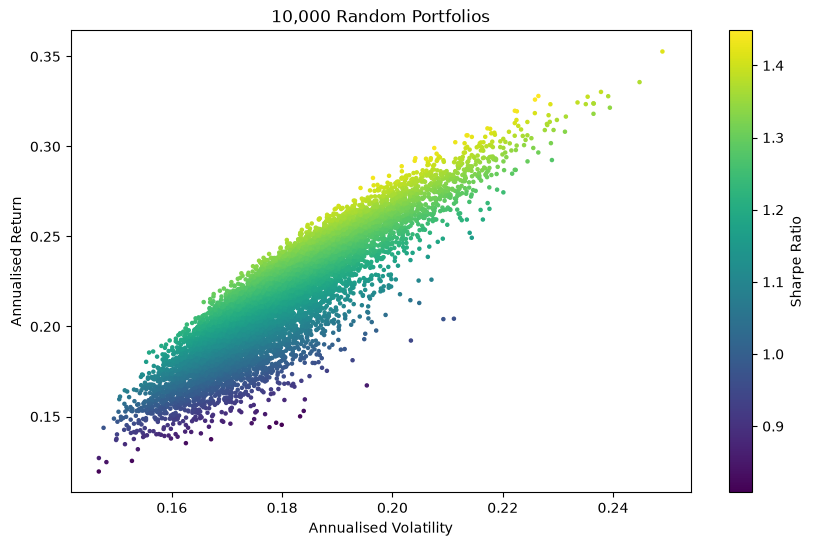

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(portfolios["Volatility"], portfolios["Return"],
            c=portfolios["Sharpe_Ratio"], cmap="viridis", s=5)

plt.colorbar(label="Sharpe Ratio")
plt.xlabel("Annualised Volatility")
plt.ylabel("Annualised Return")
plt.title("10,000 Random Portfolios")
plt.show()

In [30]:
from scipy.optimize import minimize

def portfolio_vol(w):
    return np.sqrt(w.T @ ann_cov @ w)

In [31]:
#finding the minimum variance portfolio

constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
bounds = tuple((0, 1) for _ in range(n_assets))
initial = np.repeat(1/n_assets, n_assets)

min_vol = minimize(portfolio_vol, initial, bounds=bounds, constraints=constraints)

print(min_vol.x)
print(min_vol.fun)

[0.02222641 0.02270449 0.27782647 0.         0.24759471 0.
 0.00117149 0.15783161 0.20307387 0.06757096]
0.1437399250655859
